
# **Flight Fare Prediction**

This project aims to predict flight ticket prices using Machine Learning regression models.

The dataset contains information about airlines, journey details, source, destination, stops, duration, and flight prices.

###**STEP 1 — Import libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from lightgbm import LGBMRegressor

###**STEP 2 — Load dataset**

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving flight-fare.zip to flight-fare.zip


In [ ]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/flight_fare')

print("Files extracted:")
print(os.listdir('/content/flight_fare'))

Files extracted:
['Flight_Fare.xlsx']


In [ ]:
import pandas as pd

df = pd.read_excel('/content/flight_fare/Flight_Fare.xlsx')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10683, 11)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


##**STEP 3 — Basic checks**

In [ ]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [ ]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 220


##**STEP 4 — EDA**

In [ ]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


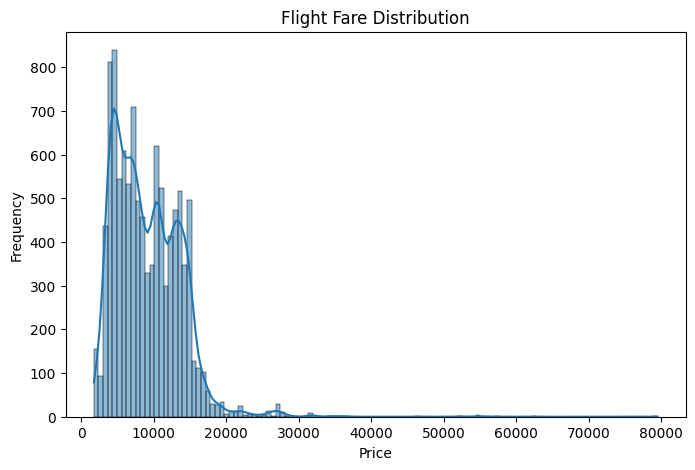

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price'], kde=True)
plt.title('Flight Fare Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

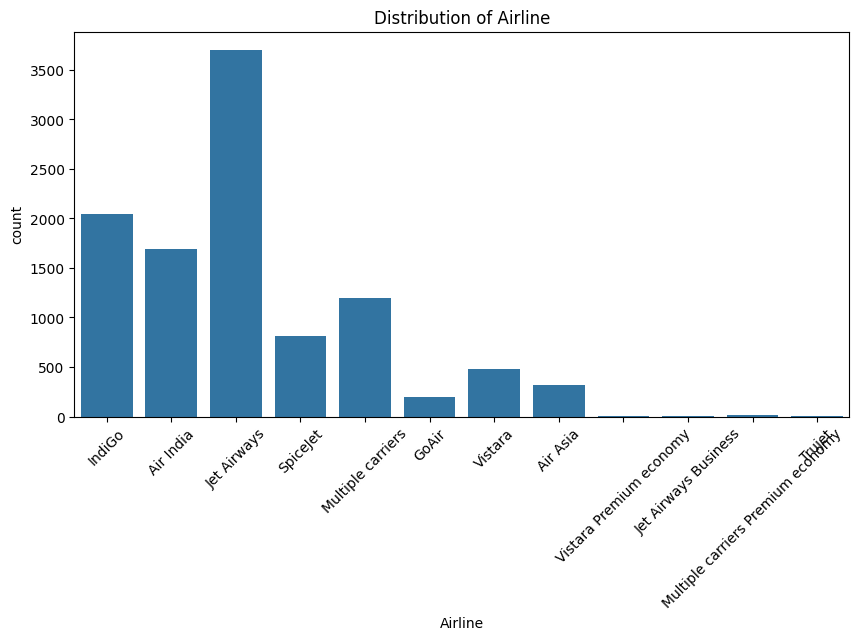

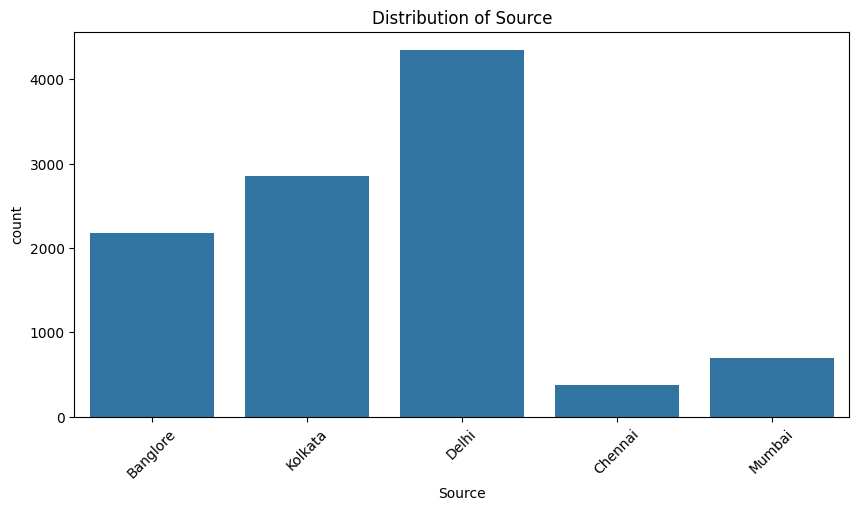

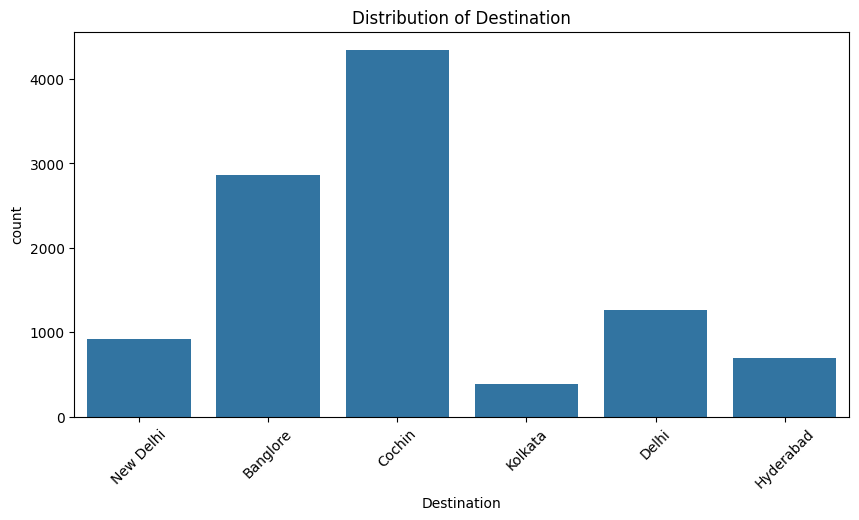

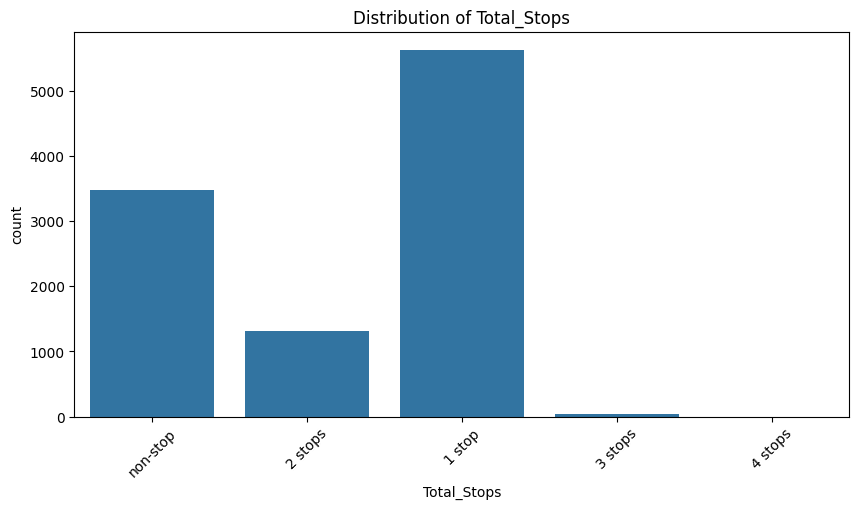

In [ ]:
# Distribution of categorical features

categorical_columns = [
    'Airline',
    'Source',
    'Destination',
    'Total_Stops'
]

for col in categorical_columns:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x=col)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)
    plt.show()

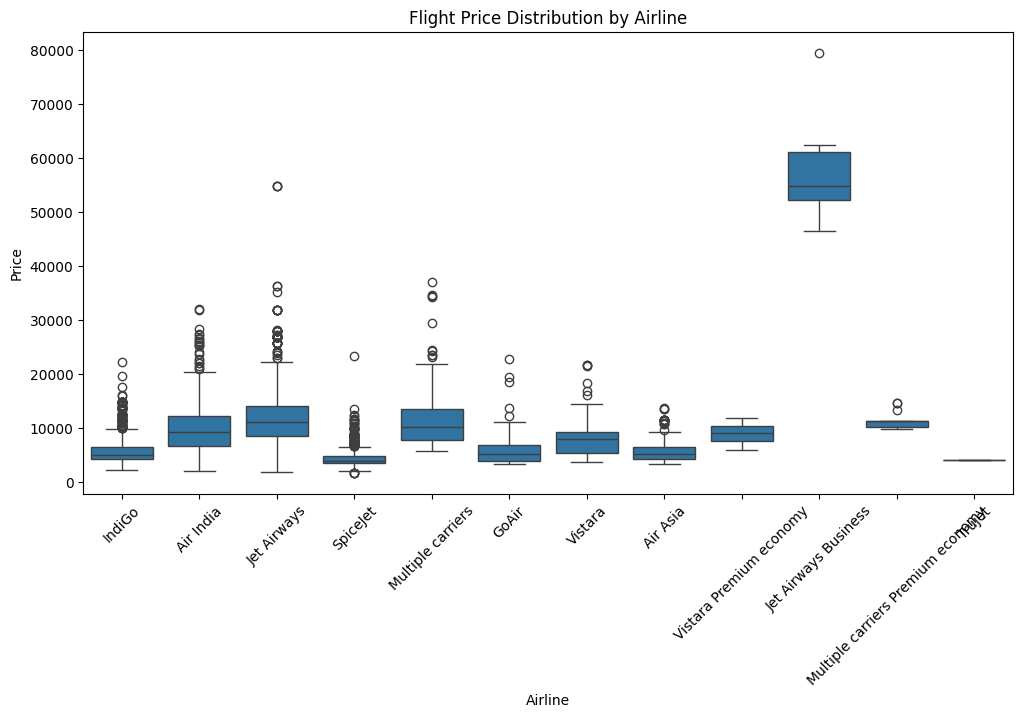

In [ ]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x='Airline', y='Price')

plt.title('Flight Price Distribution by Airline')
plt.xlabel('Airline')
plt.ylabel('Price')
plt.xticks(rotation=45)

plt.show()

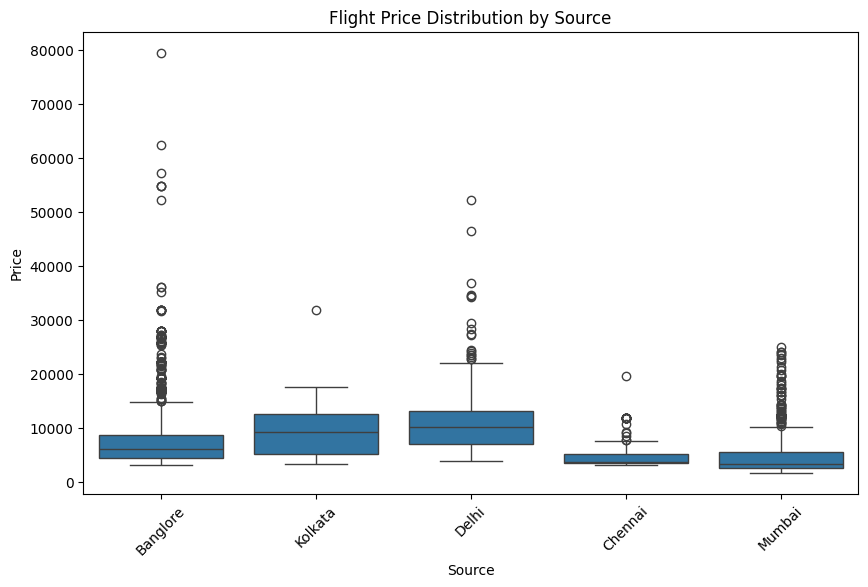

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='Source', y='Price')

plt.title('Flight Price Distribution by Source')
plt.xlabel('Source')
plt.ylabel('Price')
plt.xticks(rotation=45)

plt.show()

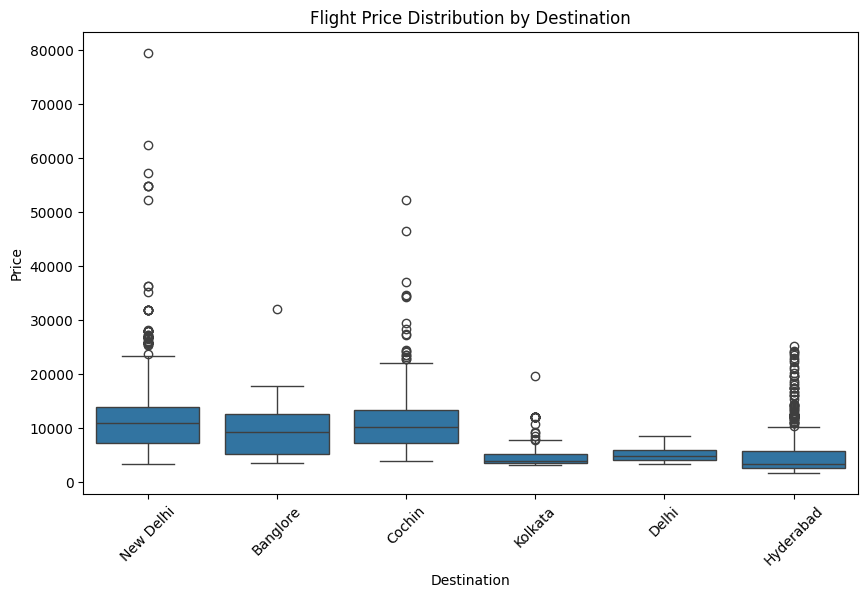

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x='Destination', y='Price')

plt.title('Flight Price Distribution by Destination')
plt.xlabel('Destination')
plt.ylabel('Price')
plt.xticks(rotation=45)

plt.show()

##**Step 5: Feature Engineering**

Feature engineering is performed to convert the existing date, time, duration,
and stop information into useful numerical features for machine learning models.

In [ ]:
# Extract day, month and year from Date_of_Journey

df['Journey_Day'] = pd.to_datetime(
    df['Date_of_Journey'],
    dayfirst=True
).dt.day

df['Journey_Month'] = pd.to_datetime(
    df['Date_of_Journey'],
    dayfirst=True
).dt.month

df['Journey_Year'] = pd.to_datetime(
    df['Date_of_Journey'],
    dayfirst=True
).dt.year

print(df[['Date_of_Journey', 'Journey_Day', 'Journey_Month', 'Journey_Year']].head())


  Date_of_Journey  Journey_Day  Journey_Month  Journey_Year
0      24/03/2019           24              3          2019
1       1/05/2019            1              5          2019
2       9/06/2019            9              6          2019
3      12/05/2019           12              5          2019
4      01/03/2019            1              3          2019


In [ ]:
# Extract hour and minute from departure and arrival time

df['Dep_Hour'] = df['Dep_Time'].str[:2].astype(int)
df['Dep_Minute'] = df['Dep_Time'].str[3:5].astype(int)

df['Arrival_Hour'] = df['Arrival_Time'].str[:2].astype(int)
df['Arrival_Minute'] = df['Arrival_Time'].str[3:5].astype(int)

print(df[['Dep_Time', 'Dep_Hour', 'Dep_Minute',
          'Arrival_Time', 'Arrival_Hour', 'Arrival_Minute']].head())

  Dep_Time  Dep_Hour  Dep_Minute  Arrival_Time  Arrival_Hour  Arrival_Minute
0    22:20        22          20  01:10 22 Mar             1              10
1    05:50         5          50         13:15            13              15
2    09:25         9          25  04:25 10 Jun             4              25
3    18:05        18           5         23:30            23              30
4    16:50        16          50         21:35            21              35


In [ ]:
# Convert Duration into total minutes

def duration_to_minutes(duration):
    parts = duration.split()

    hours = 0
    minutes = 0

    for part in parts:
        if 'h' in part:
            hours = int(part.replace('h', ''))
        elif 'm' in part:
            minutes = int(part.replace('m', ''))

    return hours * 60 + minutes

df['Duration_Minutes'] = df['Duration'].apply(duration_to_minutes)

print(df[['Duration', 'Duration_Minutes']].head())

  Duration  Duration_Minutes
0   2h 50m               170
1   7h 25m               445
2      19h              1140
3   5h 25m               325
4   4h 45m               285


In [ ]:
# Check unique values in Total_Stops

print(df['Total_Stops'].value_counts(dropna=False))

Total_Stops
1 stop      5625
non-stop    3475
2 stops     1318
3 stops       43
NaN            1
4 stops        1
Name: count, dtype: int64


In [ ]:
# Handle missing value in Total_Stops

df['Total_Stops'] = df['Total_Stops'].fillna('1 stop')

# Convert Total_Stops into numerical values

stop_mapping = {
    'non-stop': 0,
    '1 stop': 1,
    '2 stops': 2,
    '3 stops': 3,
    '4 stops': 4
}

df['Total_Stops'] = df['Total_Stops'].map(stop_mapping)

print(df['Total_Stops'].value_counts())

Total_Stops
1    5626
0    3475
2    1318
3      43
4       1
Name: count, dtype: int64


In [ ]:
# Check unique Route values

print("Number of unique routes:", df['Route'].nunique())
print("\nMissing Route values:", df['Route'].isnull().sum())

Number of unique routes: 128

Missing Route values: 1


In [ ]:
# Drop Route column

df.drop('Route', axis=1, inplace=True)

print("Route column removed.")
print("New shape:", df.shape

Route column removed.
New shape: (10463, 18)


In [ ]:
# Check Additional_Info values

print("Number of unique values:", df['Additional_Info'].nunique())
print("\nValue counts:")
print(df['Additional_Info'].value_counts())

Number of unique values: 10

Value counts:
Additional_Info
No info                         8183
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64


In [ ]:
# Drop Additional_Info column

df.drop('Additional_Info', axis=1, inplace=True)

print("Additional_Info column removed.")
print("New shape:", df.shape)

Additional_Info column removed.
New shape: (10463, 17)


##**Step 6-Train-Test Split**

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop('Price', axis=1)
y = df['Price']

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8370, 16)
X_test shape: (2093, 16)
y_train shape: (8370,)
y_test shape: (2093,)


##**STEP 7 — Target Transformation**

In [ ]:
import numpy as np

# Apply log transformation to the target
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print("Original Price:")
print(y_train.head())

print("\nLog-transformed Price:")
print(y_train_log.head())

Original Price:
6536     8327
6648    14151
3445    10844
8833     7191
3464     4544
Name: Price, dtype: int64

Log-transformed Price:
6536    9.027379
6648    9.557611
3445    9.291459
8833    8.880725
3464    8.421783
Name: Price, dtype: float64


In [ ]:
# Identify categorical and numerical columns

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Dep_Time', 'Arrival_Time', 'Duration']

Numerical columns:
['Total_Stops', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Duration_Minutes']


In [ ]:
# Drop original columns after feature extraction

columns_to_drop = [
    'Date_of_Journey',
    'Dep_Time',
    'Arrival_Time',
    'Duration'
]

X_train = X_train.drop(columns=columns_to_drop)
X_test = X_test.drop(columns=columns_to_drop)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("\nRemaining columns:")
print(X_train.columns.tolist())

X_train shape: (8370, 12)
X_test shape: (2093, 12)

Remaining columns:
['Airline', 'Source', 'Destination', 'Total_Stops', 'Journey_Day', 'Journey_Month', 'Journey_Year', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Duration_Minutes']


##**STEP 8 - Data Preprocessing pipeline**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer

# Categorical and numerical columns
categorical_cols = ['Airline', 'Source', 'Destination']

numerical_cols = [
    'Total_Stops',
    'Journey_Day',
    'Journey_Month',
    'Journey_Year',
    'Dep_Hour',
    'Dep_Minute',
    'Arrival_Hour',
    'Arrival_Minute',
    'Duration_Minutes'
]

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# Combine both
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numerical_cols),
    ('cat', categorical_pipeline, categorical_cols)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


##**STEP 9 — Linear Regression**

In [ ]:
from sklearn.linear_model import LinearRegression

# Create Linear Regression pipeline
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

print("Linear Regression pipeline created successfully.")

Linear Regression pipeline created successfully.


In [ ]:
linear_model.fit(X_train, y_train_log)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [ ]:
# Make predictions on test data
y_pred_log = linear_model.predict(X_test)

# Convert predictions back to original Price scale
y_pred = np.expm1(y_pred_log)

print("First 5 predicted prices:")
print(y_pred[:5])

First 5 predicted prices:
[12645.08754884 13353.17526396  5406.49012931 11119.60028568
  8524.26195926]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Linear Regression Results
-------------------------
MAE : 2562.8258736472862
RMSE: 3730.311711938578
R²  : 0.3330730965857045


##**STEP 10 — Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest pipeline
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


In [ ]:
rf_model.fit(X_train, y_train_log)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [ ]:
rf_pred_log = rf_model.predict(X_test)

# Convert predictions back to original Price scale
rf_pred = np.expm1(rf_pred_log)

print("First 5 predictions:")
print(rf_pred[:5])

First 5 predictions:
[13211.6164385  10845.4356776   3935.37542834  8563.93185723
  6032.70729248]


In [ ]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print("---------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R²  :", rf_r2)

Random Forest Results
---------------------
MAE : 1189.9949144210154
RMSE: 1994.438686548202
R²  : 0.8093532664396276


##**STEP 11 — Gradient Boosting**

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    ))
])

print("Gradient Boosting pipeline created successfully.")


Gradient Boosting pipeline created successfully.


In [ ]:
gb_model.fit(X_train, y_train_log)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


In [ ]:
gb_pred_log = gb_model.predict(X_test)

# Convert predictions back to original Price scale
gb_pred = np.expm1(gb_pred_log)

print("First 5 predictions:")
print(gb_pred[:5])

First 5 predictions:
[11752.67262932 11920.32792847  4518.59281319  8964.81749065
  7056.57299119]


In [ ]:
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_r2 = r2_score(y_test, gb_pred)

print("Gradient Boosting Results")
print("------------------------")
print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R²  :", gb_r2)

Gradient Boosting Results
------------------------
MAE : 1503.2004595542962
RMSE: 2259.8664663670716
R²  : 0.7552326167384533


##**STEP 12 — LightGBM**

In [ ]:
!pip install lightgbm -q


In [ ]:
from lightgbm import LGBMRegressor

lgbm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LGBMRegressor(
        n_estimators=300,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1
    ))
])

print("LightGBM pipeline created successfully.")

LightGBM pipeline created successfully.


In [ ]:
lgbm_model.fit(X_train, y_train_log)

print("LightGBM model trained successfully.")

LightGBM model trained successfully.


In [ ]:
lgbm_pred_log = lgbm_model.predict(X_test)

# Convert predictions back to original Price scale
lgbm_pred = np.expm1(lgbm_pred_log)

print("First 5 predictions:")
print(lgbm_pred[:5])

First 5 predictions:
[11629.16813914 10871.44113228  4024.26960975  8803.63941723
  6421.2663349 ]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:
lgbm_mae = mean_absolute_error(y_test, lgbm_pred)
lgbm_rmse = np.sqrt(mean_squared_error(y_test, lgbm_pred))
lgbm_r2 = r2_score(y_test, lgbm_pred)

print("LightGBM Results")
print("----------------")
print("MAE :", lgbm_mae)
print("RMSE:", lgbm_rmse)
print("R²  :", lgbm_r2)

LightGBM Results
----------------
MAE : 1174.181871039028
RMSE: 1914.8696834460522
R²  : 0.8242616938694287


##**STEP 13 - Model Comparison**

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting',
        'LightGBM'
    ],
    'MAE': [
        mae,
        rf_mae,
        gb_mae,
        lgbm_mae
    ],
    'RMSE': [
        rmse,
        rf_rmse,
        gb_rmse,
        lgbm_rmse
    ],
    'R2': [
        r2,
        rf_r2,
        gb_r2,
        lgbm_r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Linear Regression,2562.825874,3730.311712,0.333073
1,Random Forest,1189.994914,1994.438687,0.809353
2,Gradient Boosting,1503.200460,2259.866466,0.755233
3,LightGBM,1174.181871,1914.869683,0.824262


In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    lgbm_model,
    X_train,
    y_train_log,
    cv=5,
    scoring='r2'
)

print("5-Fold Cross-Validation R² Scores:")
print(cv_scores)

print("\nMean CV R²:", cv_scores.mean())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


5-Fold Cross-Validation R² Scores:
[0.88227362 0.88030639 0.89039255 0.885234   0.88901719]

Mean CV R²: 0.8854447490753314


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


##**Cross-Validation**

5-fold cross-validation was performed using the LightGBM preprocessing
pipeline.

The R² scores obtained were:

- Fold 1: 0.8823
- Fold 2: 0.8803
- Fold 3: 0.8904
- Fold 4: 0.8852
- Fold 5: 0.8890

Mean Cross-Validation R²: 0.8854

# **Sample Flight Fare Prediction**

A sample from the test dataset is used to demonstrate how the trained
LightGBM model predicts a flight fare.

In [ ]:
sample = X_test.iloc[[0]]

predicted_log = lgbm_model.predict(sample)
predicted_price = np.expm1(predicted_log)

print("Predicted Flight Fare: ₹", round(predicted_price[0], 2))
print("Actual Flight Fare: ₹", y_test.iloc[0])

Predicted Flight Fare: ₹ 11629.17
Actual Flight Fare: ₹ 15894


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


##**Challenges Faced**

During the Flight Fare Prediction project, some challenges were encountered
while preparing the data and building the machine learning models.

- The dataset contained missing values and duplicate records, which required
  proper data cleaning.

- Date, departure time, arrival time, and duration were provided in different
  formats, so they had to be converted into useful numerical features.

- Categorical features such as Airline, Source, and Destination required
  proper encoding before model training.

- Data leakage had to be avoided while applying preprocessing techniques such
  as scaling and encoding.

- The target variable Price was skewed, so log transformation was applied
  before model training.

- Different regression models were evaluated to compare their performance
  using MAE, RMSE, and R² score.

- Cross-validation was performed to check the consistency of the model
  performance.

#**conclusion**


In this project, different machine learning regression models were developed
for Flight Fare Prediction.

The models evaluated were:

- Linear Regression
- Random Forest Regressor
- Gradient Boosting Regressor
- LightGBM Regressor

A preprocessing Pipeline was used to handle numerical and categorical features
and to prevent data leakage.

MinMaxScaler was fitted only on the training data, and OrdinalEncoder was used
for categorical variables.

The target variable `Price` was transformed using `log1p()` before model
training and converted back to the original price scale using `expm1()` during
prediction.

The models were evaluated using MAE, RMSE, and R².

LightGBM obtained an R² score of 0.8243 on the test data, with an MAE of
1174.18 and RMSE of 1914.87.

5-fold cross-validation was also performed on the LightGBM pipeline, with a
mean R² score of 0.8854.

The final model can be used to predict flight fares based on the available
flight-related features.